# Setup

In [1]:
# # Colab Setup
# !git clone https://github.com/fastai/course22p2.git
# %cd course22p2
# !pip install -q fastcore einops datasets timm
# import sys
# sys.path.append('/content/course22p2')
# !pip install -q k-diffusion fastcore einops datasets timm
# !pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
# !pip install -q fastcore einops datasets timm k-diffusion
# !pip install -q torcheval fastcore einops datasets timm k-diffusion
# !pip install -q numpy==1.26.4 --force-reinstalla

# import os
# os.environ['CUDA_VISIBLE_DEVICES']='0'

In [2]:
# Kaggle Setup
!git clone https://github.com/fastai/course22p2.git
!pip install -q numpy --upgrade          # upgrade numpy FIRST
!pip install -q fastcore einops datasets timm k-diffusion torcheval

fatal: destination path 'course22p2' already exists and is not an empty directory.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dctorch 0.1.2 requires numpy<2.0.0,>=1.22.3, but you have numpy 2.4.6 which is incompatible.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.4.6 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but

In [3]:
# Kaggle Setup
import sys
sys.path.append('/kaggle/working/course22p2')
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'

In [4]:
from miniai.imports import *
from miniai.diffusion import *

from glob import glob
from fastprogress import progress_bar
from diffusers import AutoencoderKL, UNet2DConditionModel

import timm
import shutil



torch.set_printoptions(precision=4, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'
mpl.rcParams['figure.dpi'] = 70

set_seed(42)
if fc.defaults.cpus>8: fc.defaults.cpus=8

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


# Data Processing

In [ ]:
path_data = Path('data')
path_data.mkdir(exist_ok=True)
path = path_data/'bedroom'

In [ ]:
url = 'https://s3.amazonaws.com/fast-ai-imageclas/bedroom.tgz'
if not path.exists():
  path_zip = fc.urlsave(url, path_data)
  shutil.unpack_archive('data/bedroom.tgz', 'data')

In [5]:
bs = 64

In [6]:
def to_img(b): return read_image(b, mode=ImageReadMode.RGB)/255

- `read_image` is from pytorch and it is faster than `PIL` and also it is flexible as for the `ImageReadMode.RGB` bec. if the image was `1 channel` or `4 channels` it is going to make it 3 by dublicating,etc..

In [ ]:
class ImageDS:
  def __init__(self, spec, path=path):
    self.path = Path(path)
    self.files = glob(str(spec), recursive=True) #find what ever have the spec recusively
  def __len__(self): return len(self.files)
  def __getitem__(self,i): return to_img(self.files[i])[:, :256, :256] # crop to 256 if the image had more pixels

In [ ]:
ds = ImageDS(path/f'**/*.jpg') # to make it find all files we have to make (**/..) and (recursive=True [as in ImageDS])

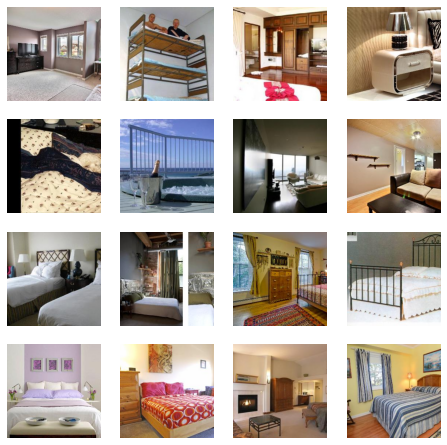

In [14]:
dl = DataLoader(ds, batch_size=bs, num_workers=4)
xb = next(iter(dl))
show_images(xb[:16], imsize=2)

In [15]:
xb[:16].shape

torch.Size([16, 3, 256, 256])

In [1]:
print(f"{16*3*256*256:,d}")

3,145,728


# VAE

In [17]:
# get pretrained VAE
vae = AutoencoderKL.from_pretrained('stabilityai/sd-vae-ft-ema').cuda().requires_grad_(False)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

In [ ]:
xbe = vae.encode(xb.cuda())

In [19]:
xbs = xbe.latent_dist.mean[:16]
xbs.shape

torch.Size([16, 4, 32, 32])

      VAE trains by outputting mean + log_variance per latent dim
      during training: sample = mean + noise*variance
        → model learns that anything near mean = same image
        → forces smooth latent space

      during inference: just take .mean (`.latent_dist.mean`)
        → skip the noise, take the center point directly
        → deterministic, consistent output


In [2]:
(16*3*256*256)/(16*4*32*32)

48.0

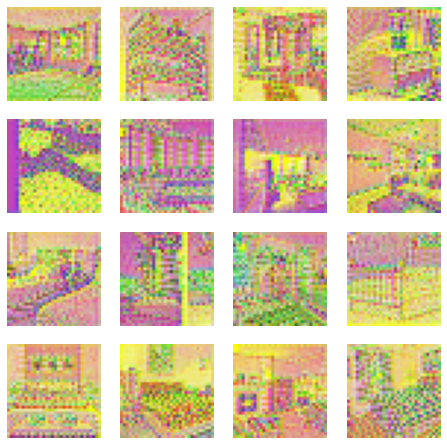

In [21]:
show_images(((xbs[:,:3])/4).sigmoid(), imsize=2)  # take first 3 channels and make it between 0 and 1

    latent values are UNBOUNDED — can be any number, -10, +50, whatever

    clipping: anything outside [0,1] gets cut flat → loses information
              latent value 5 and latent value 50 both become 1.0 → same color
              you'd see huge saturated blobs, no detail
              
    /4 first: shrinks the range before sigmoid so it doesn't saturate too fast
              without /4: large latent values hit sigmoid extremes → flat again
              with /4: values stay in the interesting middle range of sigmoid

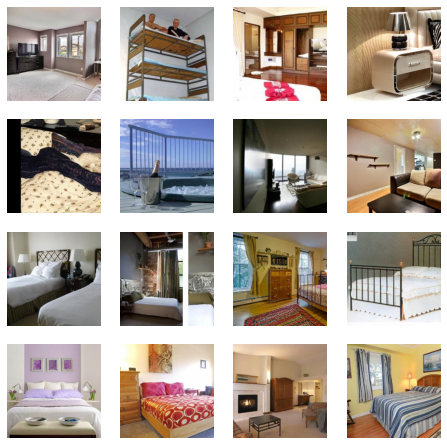

In [22]:
xbd = to_cpu(vae.decode(xbs))
show_images(xbd['sample'].clamp(0,1), imsize=2)

same thing, different names

- `torch`:      `.clamp(min, max)`
- `numpy`:    `  .clip(min, max)`

In [ ]:
mmpath = Path('/kaggle/input/datasets/seif222/latent-diffusion-encoded-ds/data.npmm')

In [24]:
len(ds)

303125

In [11]:
mmshape = (303125,4,32,32)

In [26]:
mmshape = (len(ds),4,32,32)
mmshape

(303125, 4, 32, 32)

In [27]:
if not mmpath.exists():
  a = np.memmap(mmpath, np.float32, mode='w+', shape=mmshape) # w+ to write
  i = 0
  for b in progress_bar(dl):
    n = len(b)
    a[i:i+n] = to_cpu(vae.encode(b.cuda()).latent_dist.mean).numpy()
    i += n
  a.flush() # just removed caches,etc..
  del(a) # to load it in next cell and make sure it works

<div><progress max="4737" value="4737"></progress> 100.00% [4737/4737 4:08:33&lt;00:00]</div>

    WHY:
      VAE encode is expensive → running it every training batch = slow
      solution: run it ONCE on all 303125 images (batch at a time), save latents to disk
      training then loads pre-computed latents → much faster
    WHAT np.memmap IS:
      normal array: lives in RAM → limited by RAM size
      memmap: lives on DISK but accessed like a RAM array
      303125 images × 4 channels × 32×32 latents = huge → doesn't fit in RAM
      memmap lets you read/write chunks without loading everything at once

In [12]:
lats = np.memmap(Path('/kaggle/input/datasets/seif222/latent-diffusion-encoded-ds/data.npmm'), dtype=np.float32, mode='r', shape=mmshape) # r for read

In [13]:
b = torch.tensor(lats[:16])

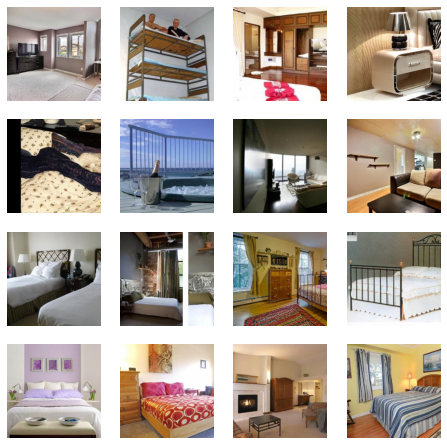

In [14]:
xbd = to_cpu(vae.decode(b.cuda()))
show_images(xbd['sample'].clamp(0,1), imsize=2)

both work for `HF models`:
  - `xbd['sample']`  ✓
  - `xbd.sample`    ✓  ← same thing

# Noisify

In [15]:
def collate_ddpm(b): return noisify(default_collate(b)*0.2)

- `VAE latents have large std`(`can be 5-7`) → `breaks diffusion noise schedule`
  `*0.2 normalizes std to ≈1` → diffusion trains stably
-  decoder always expects original scale → `must undo *0.2 before decoding`

In [16]:
n = len(lats)

In [17]:
tds = lats[:n//10*9 ] # 90% Training
vds = lats[ n//10*9:] # 10% Validation

In [18]:
bs = 128

In [19]:
dls = DataLoaders(*get_dls(tds, vds, bs, num_workers=4, collate_fn=collate_ddpm))

In [20]:
import warnings
warnings.simplefilter('ignore', UserWarning)

In [21]:
(xt,t),eps = b = next(iter(dls.train))

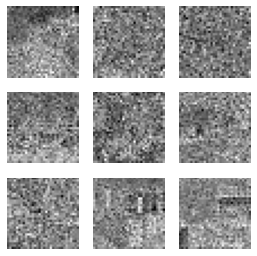

In [22]:
show_images(xt[:9,0], imsize=1.5) # noised latents

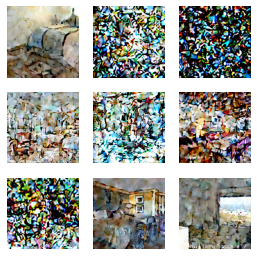

In [23]:
xte = vae.decode(xt[:9].cuda()*5)['sample'] # decode noised latents
show_images(xte.clamp(0,1), imsize=1.5)

# Train

In [24]:
def init_ddpm(model):
    for o in model.downs:
        for p in o.resnets: p.conv2[-1].weight.data.zero_()

    for o in model.ups:
        for p in o.resnets: p.conv2[-1].weight.data.zero_()

In [25]:
#@markdown FIX — patch DownBlock after import, before creating model
from einops import rearrange
from functools import wraps

def timestep_embedding(tsteps, emb_dim, max_period=10000):
    exponent = -math.log(max_period) * torch.linspace(0, 1, emb_dim//2, device=tsteps.device)
    emb = tsteps[:,None].float() * exponent.exp()[None,:]
    emb = torch.cat([emb.sin(), emb.cos()], dim=-1)
    return F.pad(emb, (0,1,0,0)) if emb_dim%2==1 else emb

def pre_conv(ni, nf, ks=3, stride=1, act=nn.SiLU, norm=None, bias=True):
    layers = nn.Sequential()
    if norm: layers.append(norm(ni))
    if act : layers.append(act())
    layers.append(nn.Conv2d(ni, nf, stride=stride, kernel_size=ks, padding=ks//2, bias=bias))
    return layers

def upsample(nf): return nn.Sequential(nn.Upsample(scale_factor=2.), nn.Conv2d(nf, nf, 3, padding=1))

def lin(ni, nf, act=nn.SiLU, norm=None, bias=True):
    layers = nn.Sequential()
    if norm: layers.append(norm(ni))
    if act : layers.append(act())
    layers.append(nn.Linear(ni, nf, bias=bias))
    return layers

class SelfAttention(nn.Module):
    def __init__(self, ni, attn_chans, transpose=True):
        super().__init__()
        self.nheads = ni//attn_chans
        self.scale = math.sqrt(attn_chans)
        self.norm = nn.LayerNorm(ni)
        self.qkv = nn.Linear(ni, ni*3)
        self.proj = nn.Linear(ni, ni)
        self.t = transpose

    def forward(self, x):
        n,c,s = x.shape
        if self.t: x = x.transpose(1,2)
        x = self.norm(x)
        qkv = self.qkv(x)
        qkv = rearrange(qkv, 'n s (h d) -> (n h) s d', h=self.nheads)
        q,k,v = torch.chunk(qkv, 3, dim=-1)
        s = (q@k.transpose(1,2)) / self.scale
        x = s.softmax(-1) @ v
        x = rearrange(x, '(n h) s d -> n s (h d)', h=self.nheads)
        x = self.proj(x)
        if self.t: x = x.transpose(1,2)
        return x

class SelfAttention2D(SelfAttention):
    def forward(self, x):
        n,c,h,w = x.shape
        return super().forward(rearrange(x, 'n c h w -> n c (h w)')).reshape(x.shape)

class EmbResBlock(nn.Module):
    def __init__(self, n_emb, ni, nf=None, act=nn.SiLU, norm=nn.BatchNorm2d, attn_chans=0):
        super().__init__()
        if nf is None: nf = ni
        self.lin_emb = nn.Linear(n_emb, nf*2)
        self.conv1 = pre_conv(ni, nf, act=act, norm=norm)
        self.conv2 = pre_conv(nf, nf, act=act, norm=norm)
        self.idconv = fc.noop if ni==nf else nn.Conv2d(ni, nf, kernel_size=1)
        self.attn = SelfAttention2D(nf, attn_chans) if attn_chans else False

    def forward(self, x, t):
        inp = x
        t_emb = self.lin_emb(F.silu(t))[:, :, None, None]
        x = self.conv1(x)
        scale, shift = torch.chunk(t_emb, 2, dim=1)
        x = x*(1+scale) + shift
        x = self.conv2(x)
        x = x + self.idconv(inp)
        if self.attn: x = x + self.attn(x)
        return x

class DownBlock(nn.Module):
    def __init__(self, n_emb, ni, nf, add_down=True, num_layers=1, attn_chans=0):
        super().__init__()
        self.resnets = nn.ModuleList([EmbResBlock(n_emb, ni if i==0 else nf, nf, attn_chans=attn_chans) for i in range(num_layers)])
        self.down = nn.Conv2d(nf, nf, 3, stride=2, padding=1) if add_down else nn.Identity()
        self.add_down = add_down

    def forward(self, x, t):
        saved = []
        for res in self.resnets:
            x = res(x, t)
            saved.append(x)          # save each resnet output
        x = self.down(x)
        if self.add_down: saved.append(x)  # save downsampled output
        return x, saved               # return BOTH x and saved → no closure needed

class UpBlock(nn.Module):
    def __init__(self, n_emb, ni, prev_nf, nf, add_up=True, num_layers=2, attn_chans=0):
        super().__init__()
        self.resnets = nn.ModuleList([EmbResBlock(n_emb, (prev_nf if i==0 else nf)+(ni if (i==num_layers-1) else nf), nf, attn_chans=attn_chans) for i in range(num_layers)])
        self.up = upsample(nf) if add_up else nn.Identity()

    def forward(self, x, t, ups):
        for resnet in self.resnets: x = resnet(torch.cat([x, ups.pop()], dim=1), t)
        return self.up(x)

class EmbUNetModel(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, nfs=(224,448,672,896), num_layers=1, attn_chans=8, attn_start=1):
        super().__init__()
        self.conv_in = nn.Conv2d(in_channels, nfs[0], kernel_size=3, padding=1)
        self.n_temb = nf = nfs[0]
        n_emb = nf*4
        self.emb_mlp = nn.Sequential(lin(self.n_temb, n_emb, norm=nn.BatchNorm1d),
                                     lin(n_emb, n_emb))
        self.downs = nn.ModuleList()
        n = len(nfs)
        for i in range(n):
            ni = nf
            nf = nfs[i]
            self.downs.append(DownBlock(n_emb, ni, nf, add_down=(i!=n-1), num_layers=num_layers, attn_chans=0 if i<attn_start else attn_chans))
        self.mid_block = EmbResBlock(n_emb, nfs[-1])
        rev_nfs = list(reversed(nfs))
        nf = rev_nfs[0]
        self.ups = nn.ModuleList()
        for i in range(n):
            prev_nf = nf
            nf = rev_nfs[i]
            ni = rev_nfs[min(i+1, n-1)]
            self.ups.append(UpBlock(n_emb, ni, prev_nf, nf, add_up=(i!=n-1), num_layers=num_layers+1, attn_chans=attn_chans if i<n-attn_start else 0))
        self.conv_out = pre_conv(nfs[0], out_channels, act=nn.SiLU, norm=nn.BatchNorm2d, bias=False)

    def forward(self, inp):
        x, t = inp
        temb = timestep_embedding(t, self.n_temb)
        emb = self.emb_mlp(temb)
        x = self.conv_in(x)
        saved = [x]
        for block in self.downs:
            x, block_saved = block(x, emb)   # unpack both x and saved
            saved += block_saved
        x = self.mid_block(x, emb)
        for block in self.ups: x = block(x, emb, saved)
        return self.conv_out(x)

In [26]:
model = EmbUNetModel(in_channels=4, out_channels=4, nfs=(128, 256, 512, 768), num_layers=2, attn_start=1, attn_chans=16) # our UNetModel
init_ddpm(model)

In [32]:
model = nn.DataParallel(model)

In [ ]:
lr = 3e-3
epochs = 25
opt_func = partial(optim.AdamW, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), MixedPrecision(), SaveCB()]
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

In [ ]:
learn.fit(epochs)

Trained it for about 7 epochs, because more epochs would crash the memory and take very long time, so i found that the model was performing fine to some point and everything was working as intended, so moved on to save time and resources

# Sampling

In [35]:
sz = (16,4,32,32)

In [43]:
model = model.to(def_device)

In [56]:
with torch.no_grad():
    preds = sample(ddim_step, model.module, sz, steps=100, eta=1., clamp=False)

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:09&lt;00:00]</div>

In [57]:
s = preds[-1]*5 # reverse the 0.2 we made for the diffuser so that decoder works fine

In [58]:
with torch.no_grad(): pd = to_cpu(vae.decode(s.cuda()))

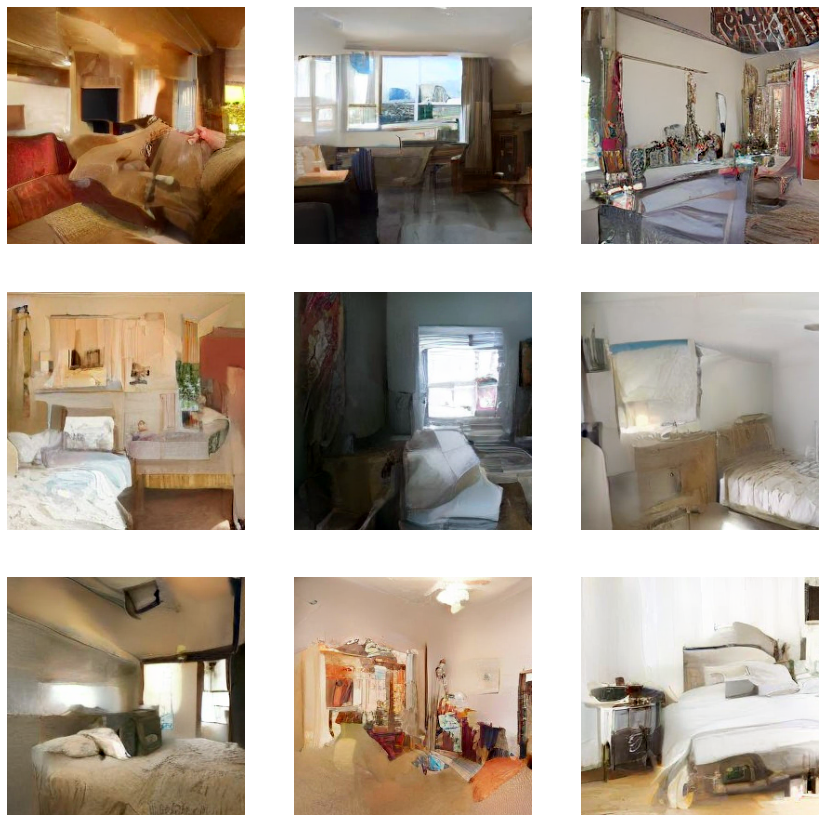

In [59]:
show_images(pd['sample'][:9].clamp(0,1), imsize=5)

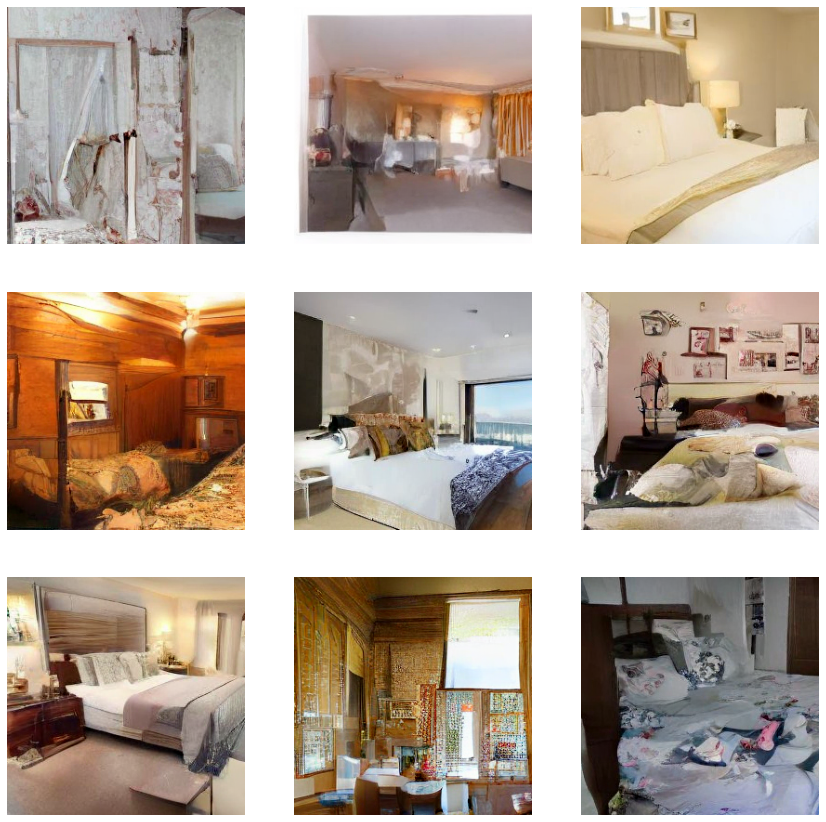
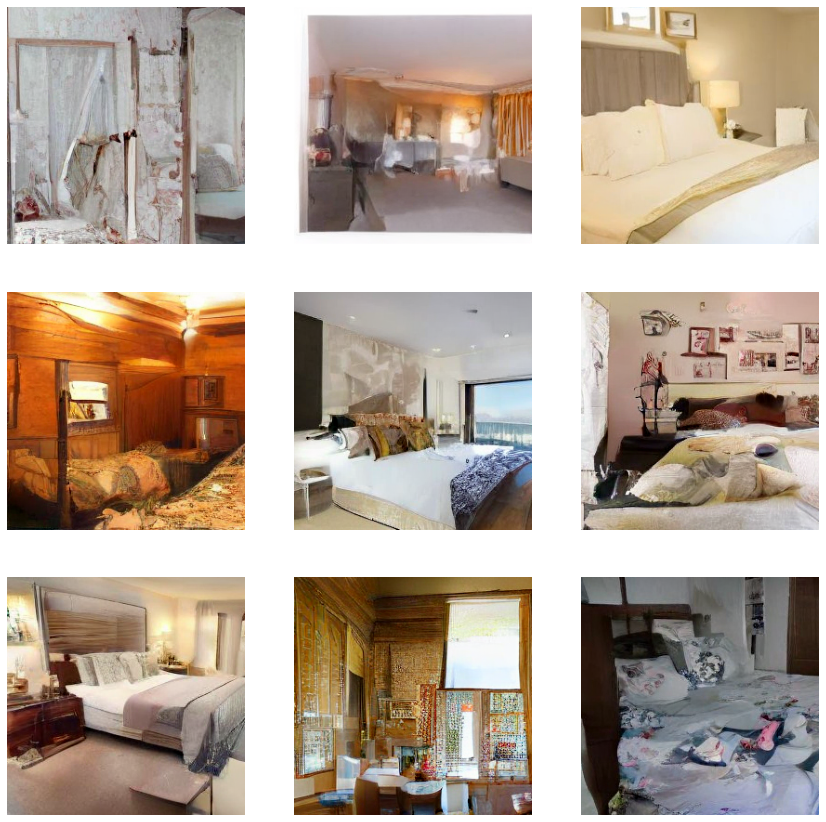